# Contador aproximado (sloppy counter), versión de las diapositivas

Este notebook grafica los resultados de los dos benchmarks de esta carpeta:

- `results_sloppy.csv` (`./benchmark_sloppy`): 1, 2, 4, 8 y 16 hilos, un millón de incrementos por hilo, umbral S = 1024 (diapositivas p. 24).
- `results_thresh_amt1.csv` (`./benchmark_thresh`): 4 hilos, un millón de incrementos por hilo, S de 1 a 1024 (diapositivas p. 25).

Para comparar, también lee `../precise_counter/results_lock.csv`, obtenido con los mismos parámetros.

> **Importante:** el notebook debe ejecutarse desde esta carpeta.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

sloppy = pd.read_csv("results_sloppy.csv")
thresh = pd.read_csv("results_thresh_amt1.csv")
precise = pd.read_csv("../precise_counter/results_lock.csv")

## 1. El valor es aproximado

`get()` solo lee `global`. Lo que quedó en los contadores locales sin llegar al umbral no se transfiere y no aparece en el resultado. Ese residuo no es aleatorio: con `amt = 1`, cada contador local transfiere exactamente cada S incrementos, así que al final le quedan (incrementos que recibió) mod S.

In [2]:
sloppy["Diferencia"] = sloppy["Expected"] - sloppy["Actual"]
sloppy

,Threads,Time(s),Expected,Actual,Diferencia
0,1,0.0406,1000000,999424,576
1,2,0.1524,2000000,1998848,1152
2,4,0.2620,4000000,3997696,2304
3,8,0.4399,8000000,7995392,4608
4,16,0.9105,16000000,15998976,1024


## 2. Tiempo vs. número de hilos (comparado con el contador preciso)

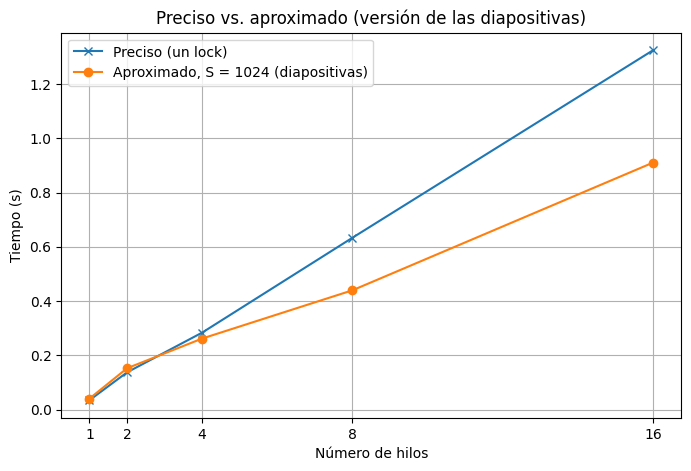

In [3]:
plt.figure(figsize=(8, 5))
plt.plot(precise["Threads"], precise["Time(s)"], marker="x", label="Preciso (un lock)")
plt.plot(sloppy["Threads"], sloppy["Time(s)"], marker="o", label="Aproximado, S = 1024 (diapositivas)")
plt.xlabel("Número de hilos")
plt.ylabel("Tiempo (s)")
plt.title("Preciso vs. aproximado (versión de las diapositivas)")
plt.xticks(sloppy["Threads"])
plt.grid(True)
plt.legend()
plt.show()

## 3. Tiempo vs. umbral S (4 hilos)

,Threshold,Time(s),Expected,Actual,Diferencia
0,1,0.5499,4000000,4000000,0
1,2,0.3659,4000000,4000000,0
2,4,0.3296,4000000,4000000,0
3,8,0.3303,4000000,4000000,0
4,16,0.3179,4000000,4000000,0
5,32,0.3736,4000000,4000000,0
6,64,0.3167,4000000,4000000,0
7,128,0.3059,4000000,3999744,256
8,256,0.3099,4000000,3999744,256
9,512,0.2987,4000000,3999744,256


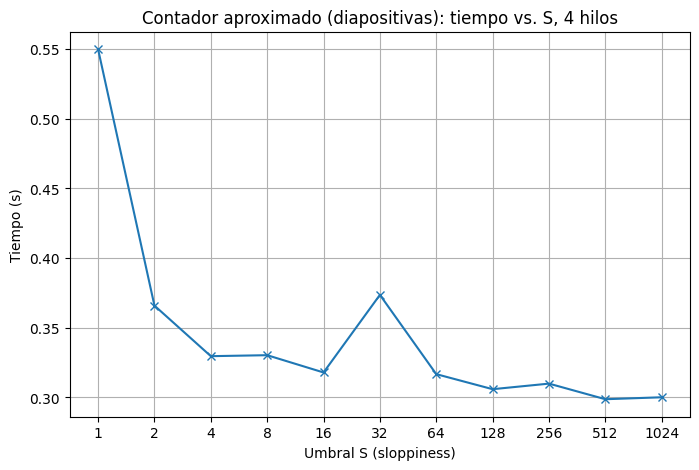

In [4]:
thresh["Diferencia"] = thresh["Expected"] - thresh["Actual"]
display(thresh)

plt.figure(figsize=(8, 5))
plt.plot(thresh["Threshold"], thresh["Time(s)"], marker="x")
plt.xscale("log", base=2)
plt.xticks(thresh["Threshold"], thresh["Threshold"])
plt.xlabel("Umbral S (sloppiness)")
plt.ylabel("Tiempo (s)")
plt.title("Contador aproximado (diapositivas): tiempo vs. S, 4 hilos")
plt.grid(True)
plt.show()

## Observaciones

- **Exactitud.** Con S = 1 el valor es exacto. A medida que S crece, el residuo puede crecer (hasta S − 1 por contador local), y el valor global se retrasa respecto al real (diapositivas p. 25).
- **Desempeño.** En la máquina de referencia, con pocos hilos esta versión es incluso un poco más lenta que el contador preciso (cada incremento toma un lock local además de, a veces, el global), y con muchos hilos es solo algo más rápida. En el barrido de S, a partir de S = 4 el tiempo casi no baja. Esto **no** se parece a las gráficas de OSTEP de las diapositivas (p. 24 y 25), donde el contador aproximado es casi plano y el tiempo cae con S.

La causa no está en la lógica del contador sino en cómo quedan sus datos en memoria: los 8 contadores locales (`int local[NUMCPUS]`) caben en una sola línea de caché, así que los hilos que actualizan contadores distintos se invalidan esa línea entre sí en cada incremento (*false sharing*). La carpeta `../comparison/` repite los dos experimentos con cada contador local en su propia línea de caché.